<a href="https://colab.research.google.com/github/LeonardoSaavedra-07/Artificial-Intelligence/blob/main/Practica_7_Segmentacion_Optima_(2).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Práctica 7. Segmentación óptima
**Procesamiento Digital de Imágenes — UANL FIME**

**Brígada:** 309 , **Carrera:** IB

**Integrantes:**

Leonardo Saavedra de León - 2093442

Alejandra Janeth Hernández Grimaldo - 1929944

Erick Alejandro Cantú Plascencia - 2105789

Manuel Alejandro Juárez Grimaldo - 2115290

**Objetivo:** segmentar un área de interés (tumor) en una imagen médica mediante segmentación óptima, usando SLSQP para encontrar los coeficientes óptimos de los canales R, G y B.

## 1. Librerías e imagen
Se importan OpenCV, NumPy, Matplotlib y SciPy (para `minimize` con el método SLSQP). La imagen `Te-me_0015.jpg` se descarga del repositorio de la clase.

Tamaño de la imagen: (605, 507, 3)


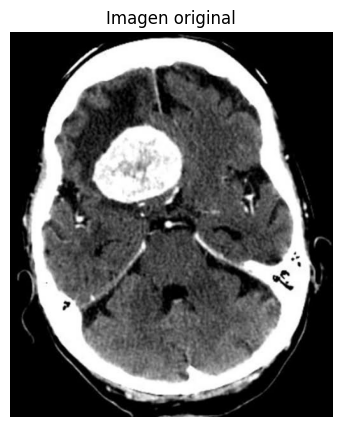

In [1]:
import urllib.request
import cv2
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

URL = "https://raw.githubusercontent.com/dilp90/PDI/main/Imagenes/Te-me_0015.jpg"
urllib.request.urlretrieve(URL, "Te-me_0015.jpg")

bgr = cv2.imread("Te-me_0015.jpg")
rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
R, G, B = [rgb[:, :, i].astype(np.float64) for i in range(3)]
print("Tamaño de la imagen:", rgb.shape)

plt.figure(figsize=(5, 5))
plt.imshow(rgb); plt.title("Imagen original"); plt.axis("off"); plt.show()

## 2. Canales R, G y B
Se visualiza cada canal por separado para ver cuál resalta mejor las estructuras de interés.

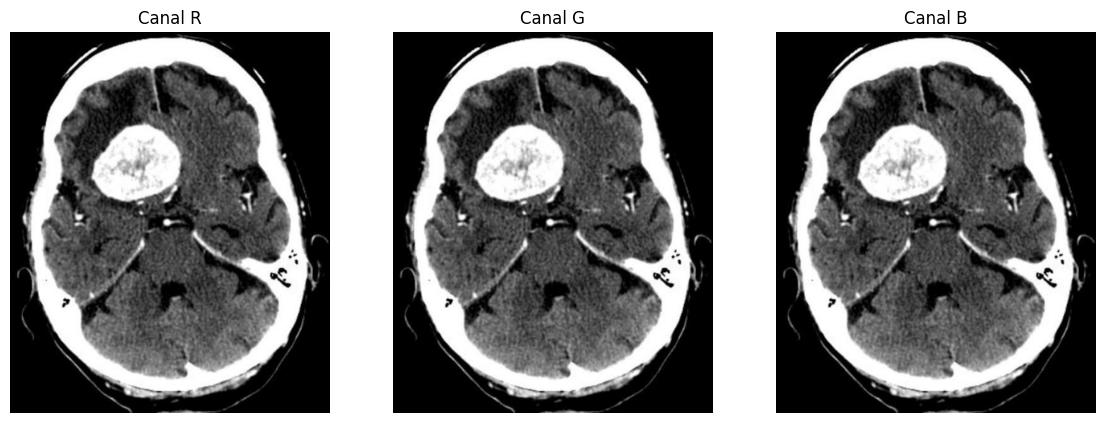

In [2]:
fig, ax = plt.subplots(1, 3, figsize=(14, 5))
for a, canal, nombre in zip(ax, (R, G, B), ("R", "G", "B")):
    a.imshow(canal, cmap="gray", vmin=0, vmax=255); a.set_title(f"Canal {nombre}"); a.axis("off")
plt.show()

## 3. Segmentación sencilla
Se convierte a escala de grises **promediando los canales** (R+G+B)/3 y se segmenta con un umbral fijo, igual que en el notebook de referencia.

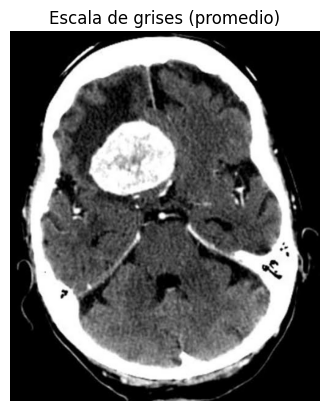

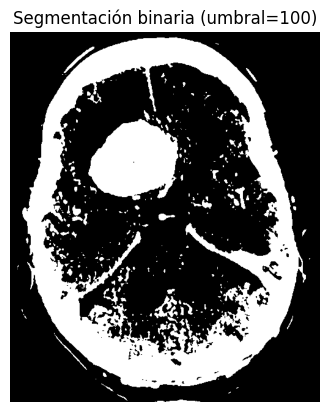

In [3]:
gris_prom = ((R.astype(np.float32) + G + B) / 3).astype(np.uint8)

plt.imshow(gris_prom, cmap='gray'); plt.title('Escala de grises (promedio)'); plt.axis('off'); plt.show()

UMBRAL = 100   # ajustar según la imagen
_, segmentada = cv2.threshold(gris_prom, UMBRAL, 255, cv2.THRESH_BINARY)

plt.imshow(segmentada, cmap='gray'); plt.title(f'Segmentación binaria (umbral={UMBRAL})'); plt.axis('off'); plt.show()

## 4. Segmentación óptima con SLSQP
**Objetivo:** encontrar los coeficientes óptimos [w_r, w_g, w_b] para convertir la imagen RGB a escala de grises:

Gris(i,j) = w_r·R(i,j) + w_g·G(i,j) + w_b·B(i,j),  con w_r + w_g + w_b = 1

**Criterio:** maximizar la varianza de la imagen en grises normalizada (mayor varianza ≡ mayor contraste). Como `minimize()` minimiza, la función objetivo devuelve la **varianza negativa**.

**Método:** SLSQP (Sequential Least Squares Programming), con restricción de igualdad (suma de pesos = 1) y límites de 0 a 1 para cada peso. Punto inicial: [0.33, 0.33, 0.34].

In [4]:
# Canales normalizados entre 0 y 1
R_norm = R.astype(np.float32) / 255
G_norm = G.astype(np.float32) / 255
B_norm = B.astype(np.float32) / 255

# ¿Los tres canales son iguales? (imagen realmente en escala de grises)
print("Canales idénticos:", np.array_equal(rgb[:,:,0], rgb[:,:,1]) and np.array_equal(rgb[:,:,1], rgb[:,:,2]))

def grayscale_variance(weights):
    w_r, w_g, w_b = weights
    gray = w_r * R_norm + w_g * G_norm + w_b * B_norm
    rango = gray.max() - gray.min()
    if rango < 1e-9:
        return 0.0
    gray_normalized = (gray - gray.min()) / rango
    return -np.var(gray_normalized)      # negativo para maximizar

constraints = ({'type': 'eq', 'fun': lambda w: np.sum(w) - 1})
bounds = [(0, 1), (0, 1), (0, 1)]
initial_weights = [0.33, 0.33, 0.34]

result = minimize(grayscale_variance, initial_weights, method='SLSQP',
                  bounds=bounds, constraints=constraints)
optimal_weights = result.x
print("Pesos óptimos:", optimal_weights)
print("Suma de pesos:", optimal_weights.sum())
print("Varianza con promedio (1/3 c/u):", -grayscale_variance([1/3, 1/3, 1/3]))
print("Varianza con pesos óptimos      :", -result.fun)

Canales idénticos: True
Pesos óptimos: [0.33 0.33 0.34]
Suma de pesos: 1.0
Varianza con promedio (1/3 c/u): 0.12693979
Varianza con pesos óptimos      : 0.1269397689490458


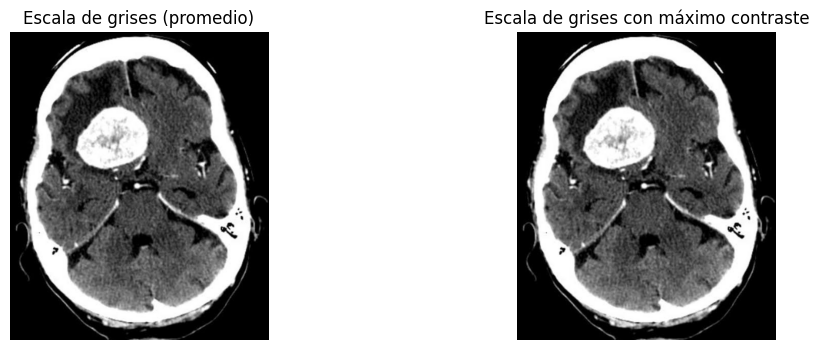

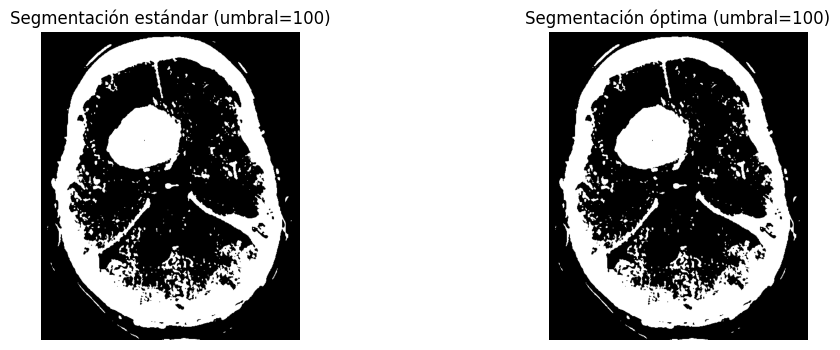

In [5]:
gris_optimo = optimal_weights[0]*R_norm + optimal_weights[1]*G_norm + optimal_weights[2]*B_norm
gris_optimo = ((gris_optimo - gris_optimo.min()) / (gris_optimo.max() - gris_optimo.min()) * 255).astype(np.uint8)

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1); plt.imshow(gris_prom, cmap='gray'); plt.title('Escala de grises (promedio)'); plt.axis('off')
plt.subplot(1, 2, 2); plt.imshow(gris_optimo, cmap='gray'); plt.title('Escala de grises con máximo contraste'); plt.axis('off')
plt.show()

# Segmentar ambas con el mismo umbral
_, seg_estandar = cv2.threshold(gris_prom, UMBRAL, 255, cv2.THRESH_BINARY)
_, seg_optimal = cv2.threshold(gris_optimo, UMBRAL, 255, cv2.THRESH_BINARY)

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1); plt.imshow(seg_estandar, cmap='gray'); plt.title(f'Segmentación estándar (umbral={UMBRAL})'); plt.axis('off')
plt.subplot(1, 2, 2); plt.imshow(seg_optimal, cmap='gray'); plt.title(f'Segmentación óptima (umbral={UMBRAL})'); plt.axis('off')
plt.show()

## 5. Eliminación de ruido
Se aplica un filtro de mediana, apertura y cierre morfológicos, y se eliminan los componentes conexos pequeños. Si el resultado resalta el fondo en lugar de las estructuras, cambiar `INVERTIR` a `True`.

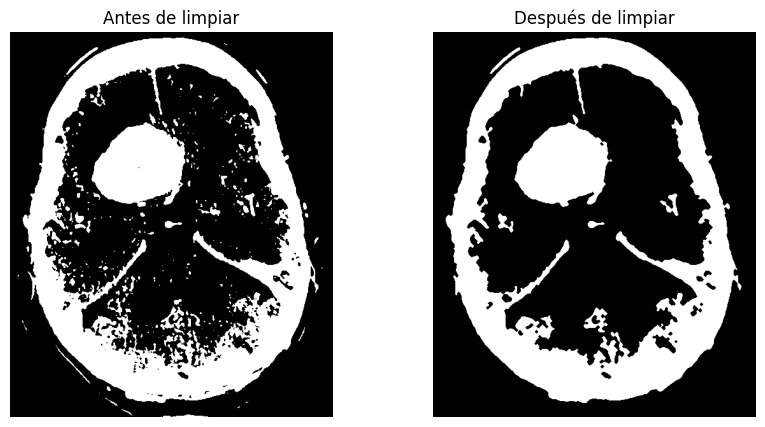

In [6]:
INVERTIR = False        # poner True si la máscara quedó invertida (estructuras en negro)
AREA_MIN = 150          # píxeles mínimos para conservar un componente (ajustar)

def quitar_componentes_pequenos(mascara, area_min):
    n, etiquetas, stats, _ = cv2.connectedComponentsWithStats(mascara, connectivity=8)
    limpia = np.zeros_like(mascara)
    for i in range(1, n):
        if stats[i, cv2.CC_STAT_AREA] >= area_min:
            limpia[etiquetas == i] = 255
    return limpia

mascara = cv2.bitwise_not(seg_optimal) if INVERTIR else seg_optimal.copy()
mascara = cv2.medianBlur(mascara, 5)
k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
mascara = cv2.morphologyEx(mascara, cv2.MORPH_OPEN, k, iterations=1)
mascara = cv2.morphologyEx(mascara, cv2.MORPH_CLOSE, k, iterations=2)
mascara_limpia = quitar_componentes_pequenos(mascara, AREA_MIN)

fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].imshow(seg_optimal, cmap="gray"); ax[0].set_title("Antes de limpiar")
ax[1].imshow(mascara_limpia, cmap="gray"); ax[1].set_title("Después de limpiar")
for a in ax: a.axis("off")
plt.show()

## 6. Contornos del cráneo y del tumor
En la máscara limpia, el cráneo es un anillo conectado y el tumor es una región blanca **separada** de él. Con componentes conexos:

- **Cráneo:** el componente de mayor área. Se dibujan su contorno externo y su contorno interno (grosor del hueso).
- **Tumor:** el componente de mayor área (distinto del cráneo) cuyo centro queda dentro del cráneo. Se rellenan sus huecos internos con su contorno externo.

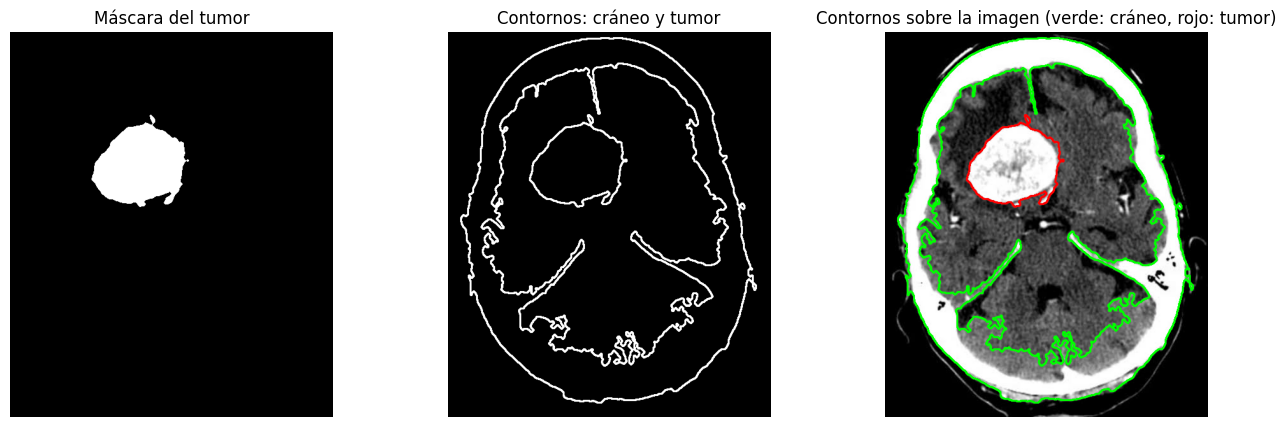

In [7]:
AREA_MIN_TUMOR = 150   # área mínima (px) para considerar un componente como tumor

n, etiquetas, stats, centroides = cv2.connectedComponentsWithStats(mascara_limpia, connectivity=8)

# --- Cráneo: componente de mayor área ---
idx_craneo = 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])
mask_hueso = (etiquetas == idx_craneo).astype(np.uint8) * 255

cont_ext, _ = cv2.findContours(mask_hueso, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
cont_craneo = max(cont_ext, key=cv2.contourArea)
mask_craneo = np.zeros_like(mask_hueso)
cv2.drawContours(mask_craneo, [cont_craneo], -1, 255, thickness=cv2.FILLED)

cont_all, jerarquia = cv2.findContours(mask_hueso, cv2.RETR_CCOMP, cv2.CHAIN_APPROX_SIMPLE)
huecos = [ct for ct, h in zip(cont_all, jerarquia[0]) if h[3] != -1]
cont_interno = max(huecos, key=cv2.contourArea) if huecos else None

# --- Tumor: mayor componente (distinto del cráneo) con centro dentro del cráneo ---
candidatos = []
for i in range(1, n):
    if i == idx_craneo:
        continue
    cx, cy = centroides[i]
    if stats[i, cv2.CC_STAT_AREA] >= AREA_MIN_TUMOR and mask_craneo[int(cy), int(cx)] > 0:
        candidatos.append((stats[i, cv2.CC_STAT_AREA], i))
assert candidatos, "No se encontró tumor: baja AREA_MIN_TUMOR o ajusta UMBRAL"
idx_tumor = max(candidatos)[1]

mask_tumor = (etiquetas == idx_tumor).astype(np.uint8) * 255
cont_t, _ = cv2.findContours(mask_tumor, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
cont_tumor = max(cont_t, key=cv2.contourArea)
mask_tumor = np.zeros_like(mask_tumor)
cv2.drawContours(mask_tumor, [cont_tumor], -1, 255, thickness=cv2.FILLED)   # rellena huecos

# --- Dibujo ---
resultado = rgb.copy()
cv2.drawContours(resultado, [cont_craneo], -1, (0, 255, 0), 2)
if cont_interno is not None:
    cv2.drawContours(resultado, [cont_interno], -1, (0, 255, 0), 2)
cv2.drawContours(resultado, [cont_tumor], -1, (255, 0, 0), 2)

solo_contornos = np.zeros_like(rgb)
cv2.drawContours(solo_contornos, [cont_craneo], -1, (255, 255, 255), 2)
if cont_interno is not None:
    cv2.drawContours(solo_contornos, [cont_interno], -1, (255, 255, 255), 2)
cv2.drawContours(solo_contornos, [cont_tumor], -1, (255, 255, 255), 2)

fig, ax = plt.subplots(1, 3, figsize=(16, 5))
ax[0].imshow(mask_tumor, cmap="gray"); ax[0].set_title("Máscara del tumor")
ax[1].imshow(solo_contornos); ax[1].set_title("Contornos: cráneo y tumor")
ax[2].imshow(resultado); ax[2].set_title("Contornos sobre la imagen (verde: cráneo, rojo: tumor)")
for a in ax: a.axis("off")
plt.show()

## 7. Área del tumor
Se calcula el área en píxeles de dos formas (contorno y conteo de píxeles de la máscara). Si se conoce la resolución de la imagen (mm/píxel), se convierte a mm².

In [8]:
area_contorno = cv2.contourArea(cont_tumor)
area_pixeles = int(np.count_nonzero(mask_tumor))
area_craneo = cv2.contourArea(cont_craneo)

print(f"Área del tumor (contourArea): {area_contorno:.1f} px²")
print(f"Área del tumor (conteo de píxeles): {area_pixeles} px²")
print(f"Proporción tumor/cráneo: {100*area_contorno/area_craneo:.2f} %")

MM_POR_PIXEL = None   # ej. 0.5 si cada píxel mide 0.5 mm; dejar None si no se conoce
if MM_POR_PIXEL:
    print(f"Área del tumor: {area_contorno * MM_POR_PIXEL**2:.2f} mm²")

Área del tumor (contourArea): 13753.5 px²
Área del tumor (conteo de píxeles): 13993 px²
Proporción tumor/cráneo: 6.85 %
